# Function for ResNet Model


In [ ]:
#The Code for the Residual Network
#It takes four inputs: shape of input pictures, filters as a list,
# kernelsize as integer, and the amount of residual blocks as a list.
#blocks and filters need to be of the same length, since they are used together
import tensorflow as tf
import numpy as np
from tensorflow import keras
from tensorflow import Tensor
from tensorflow.keras.models import Model



def res_block(x, dimred, kernelsize, filters) -> Tensor:
#Function for the residual unit. Contains 2 convolutional layers with each a
#relu activation and BatchNormalization. If amount of filter changes (dimred == True)
#size of input will be equalized by increasing stride

    conv = keras.layers.Conv2D(kernel_size=kernelsize,
                        strides= (1 if not dimred else 2),
                        filters=filters,
                        padding="same")(x)

    conv = keras.layers.ReLU()(conv)
    conv = keras.layers.BatchNormalization()(conv)

    conv = keras.layers.Conv2D(kernel_size=kernelsize,
                        strides=1,
                        filters=filters,
                        padding="same")(conv)

    if dimred:
        x = keras.layers.Conv2D(kernel_size=1,
                           strides=2,
                           filters=filters,
                           padding="same")(x)

    out = keras.layers.Add()([x, conv])
    out = keras.layers.ReLU()(out)
    out = keras.layers.BatchNormalization()(out)
    return out

def res_net(inputs, filters, kernelsize, blocks):
#Generates Residual Network with inputted information
# dimred == True if is the first residual block after the filter changes

    seq = keras.layers.BatchNormalization()(inputs)
    seq = keras.layers.Conv2D(kernel_size=3,
                       strides=1,
                       filters=filters[0],
                       padding="same")(seq)
    seq = keras.layers.ReLU()(seq)
    seq = keras.layers.BatchNormalization()(seq)

    for i in range(len(blocks)):
        for j in range(blocks[i]):
            seq = res_block(seq, dimred=(j==0 and i!=0), kernelsize=kernelsize, filters=filters[i])

    seq = keras.layers.MaxPooling2D(4)(seq)
    seq = keras.layers.Flatten()(seq)
    outputs = keras.layers.Dense(10, activation='softmax')(seq)

    model = Model(inputs, outputs)

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Function for PlainNet model

In [ ]:
import tensorflow as tf
import numpy as np
from tensorflow import keras
from tensorflow import Tensor
from tensorflow.keras.models import Model


def plain_net(inputs, filters, kernelsize, blocks):
# Same procedure as Residual Network but without the residual block and skip connection

     seq = keras.layers.BatchNormalization()(inputs)
     seq = keras.layers.Conv2D(kernel_size=kernelsize,
                strides=1,
                filters=filters[0],
                padding="same")(seq)
     seq = keras.layers.ReLU()(seq)
     seq = keras.layers.BatchNormalization()(seq)


     for i in range(len(blocks)):

         for j in range(blocks[i]):

             dimred = (j==0 and i!=0)
             seq = keras.layers.Conv2D(kernel_size= kernelsize,
                        strides= (1 if not dimred else 2),
                        filters=filters[i],
                        padding="same")(seq)
             seq = keras.layers.ReLU()(seq)
             seq = keras.layers.BatchNormalization()(seq)

     seq = keras.layers.MaxPooling2D(4)(seq)
     seq = keras.layers.Flatten()(seq)
     outputs = keras.layers.Dense(10, activation='softmax')(seq)

     model = Model(inputs, outputs)

     model.compile(
         optimizer='adam',
         loss='categorical_crossentropy',
         metrics=['accuracy']
     )

     return model

## Defining input and resizing images to 32x32

In [ ]:
# Downloading both Datasets and resizing images to 32x32
import numpy as np

mnist = tf.keras.datasets.mnist
fashion_mnist = keras.datasets.fashion_mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()
(x_fashion, y_fashion), (x_fashiontest, y_fashiontest) = fashion_mnist.load_data()


# expand new axis, channel axis
x_train = np.expand_dims(x_train, axis=-1)
x_fashion = np.expand_dims(x_fashion, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)
x_fashiontest = np.expand_dims(x_fashiontest, axis=-1)

# need 3 channels (instead of 1)
x_fashion = np.repeat(x_fashion, 3, axis=-1)
x_train = np.repeat(x_train, 3, axis=-1)
x_fashiontest = np.repeat(x_fashiontest, 3, axis=-1)
x_test = np.repeat(x_test, 3, axis=-1)

# it's always better to normalize
x_train = x_train.astype('float32') / 255
x_fashion = x_fashion.astype('float32') / 255
x_test = x_test.astype('float32') / 255
x_fashiontest = x_fashiontest.astype('float32') / 255


# resize the input shape , i.e. old shape: 28, new shape: 32
x_train = tf.image.resize(x_train, [32,32])
x_fashion = tf.image.resize(x_fashion, [32,32])
x_test = tf.image.resize(x_test, [32,32])
x_fashiontest = tf.image.resize(x_fashiontest, [32,32])

# one hot
y_train = tf.keras.utils.to_categorical(y_train , num_classes=10)
y_fashion = tf.keras.utils.to_categorical(y_fashion , num_classes=10)
y_test = tf.keras.utils.to_categorical(y_test , num_classes=10)
y_fashiontest = tf.keras.utils.to_categorical(y_fashiontest , num_classes=10)


print(x_train.shape, y_train.shape)

(60000, 32, 32, 3) (60000, 10)


In [ ]:
# Input for generating a ResNet, shape of input needs to be 32x32 because keras does not allow it to be smaller
inputs = keras.Input(shape=(32, 32, 3))
filters = [64, 128, 256, 512]
blocks = [3, 6, 6, 3]
kernelsize = 3

In [ ]:
#Just for an example run with resnet
#saves history with values after each epoch for plotting long time running behaviour
#needs a GPU to run otherwise it will take days to finish

resinet_fashion = res_net(inputs, filters, kernelsize, blocks)
history_fashion = resinet_fashion.fit(x_fashion, y_fashion, batch_size=256, epochs=50, verbose =  1, validation_data=(x_fashiontest, y_fashiontest))
fashionnet_loss = history_fashion.history["loss"]
fashionnet_accu = history_fashion.history["accuracy"]
fashionnet_valloss = history_fashion.history["val_loss"]
fashionnet_valaccu = history_fashion.history["val_accuracy"]
resnet_fashion_values = np.array([fashionnet_loss, fashionnet_accu, fashionnet_valloss, fashionnet_valaccu])
np.savetxt("resnet_fashion_values.csv", resnet_fashion_values, delimiter=",")
resinet_fashion.save("fashion_resi_net")

In [ ]:
# Just for an example run with plainnet
# Uses different set of blocks because every residual block consists of 2 conv layers, but overall same amount
plainblock = [6, 12, 12, 6]
plainnet_fashion = plain_net(inputs, filters, kernelsize, plainblock)
history_plainnet = plainnet_fashion.fit(x_fashion, y_fashion, batch_size=256, epochs=50, verbose =  1, validation_data=(x_fashiontest, y_fashiontest))
plainnet_loss = history_plainnet.history["loss"]
plainnet_accu = history_plainnet.history["accuracy"]
plainnet_valloss = history_plainnet.history["val_loss"]
plainnet_valaccu = history_plainnet.history["val_accuracy"]
plainnet_fashion_values = np.array([plainnet_loss, plainnet_accu, plainnet_valloss, plainnet_valaccu])

np.savetxt("plainnet_fashion_values.csv", plainnet_fashion_values, delimiter=",")
plainnet_fashion.save("fashion_plain_net_model")

# Plots and Rest

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

number_count_mnisttrain = np.zeros(10)
number_count_fashiontrain = np.zeros(10)
number_count_mnisttest = np.zeros(10)
number_count_fashiontest = np.zeros(10)

for i in np.arange(0,10):
  for j in np.arange(0,60000):
    if int(y_train[j][i]) == 1:
      number_count_mnisttrain[i] += 1
    if int(y_fashion[j][i]) == 1:
      number_count_fashiontrain[i] += 1

print(number_count_mnisttrain)
print(number_count_fashiontrain)


for i in np.arange(0,10):
  for j in np.arange(0,10000):
    if int(y_test[j][i]) == 1:
      number_count_mnisttest[i] += 1
    if int(y_fashiontest[j][i]) == 1:
      number_count_fashiontest[i] += 1

print(number_count_mnisttest)
print(number_count_fashiontest)


[5923. 6742. 5958. 6131. 5842. 5421. 5918. 6265. 5851. 5949.]
[6000. 6000. 6000. 6000. 6000. 6000. 6000. 6000. 6000. 6000.]
[ 980. 1135. 1032. 1010.  982.  892.  958. 1028.  974. 1009.]
[1000. 1000. 1000. 1000. 1000. 1000. 1000. 1000. 1000. 1000.]


/opt/anaconda3/lib/python3.7/site-packages/matplotlib/figure.py:445: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  % get_backend())


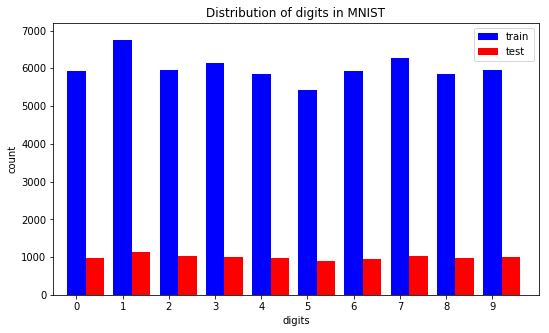

In [ ]:
fig = plt.figure(figsize=(40,5))
bar_width = 0.4
index = np.arange(10)
ax1 = fig.add_subplot(1,4,1)
ax1.bar(index, number_count_mnisttrain, bar_width, fc='b', edgecolor='none', label="train")
ax1.bar(index+bar_width, number_count_mnisttest, bar_width, fc='r', edgecolor='none', label="test")
ax1.set_xlabel("digits")
ax1.set_ylabel("count")
ax1.set_xlim(-0.5,10)
ax1.set_ylim(0, 7200)
plt.xticks(index)
ax1.legend()
ax1.set_title('Distribution of digits in MNIST')
fig.show()
fig.savefig("mnist_barplot")

/opt/anaconda3/lib/python3.7/site-packages/matplotlib/figure.py:445: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  % get_backend())


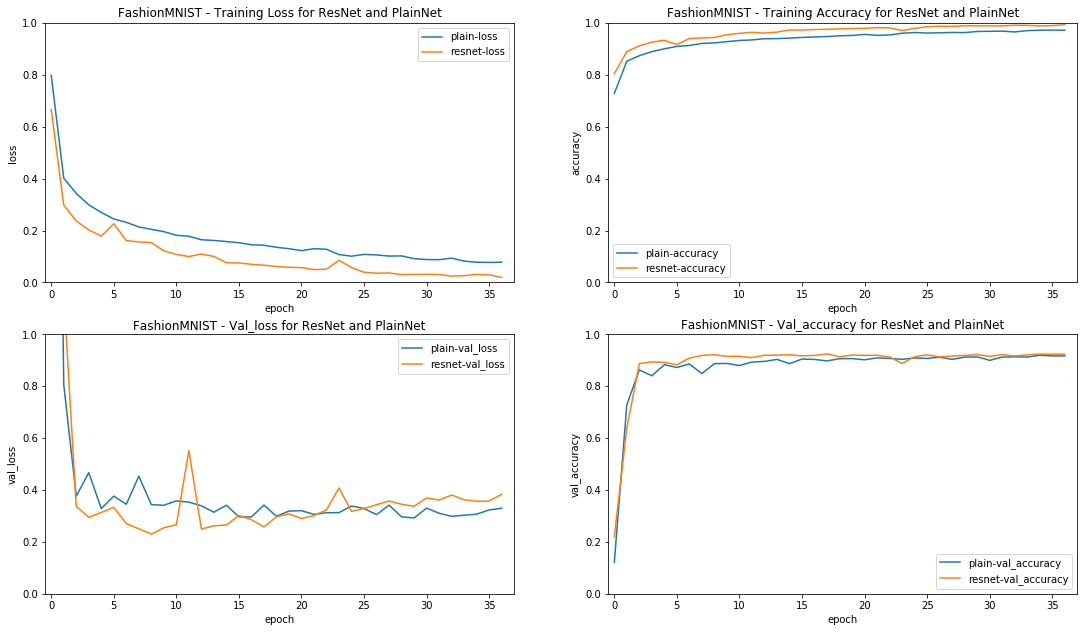

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.pyplot import figure


plainhist = np.genfromtxt("/Users/tomunterleiter/Desktop/ResNet/plainnet_fashion_values.csv", delimiter=",")
reshist = np.genfromtxt("/Users/tomunterleiter/Desktop/ResNet/resnet_fashion_values.csv", delimiter=",")


index = np.arange(37)
fig, axs = plt.subplots(2, 2)

fig.set_size_inches(18.5, 10.5)

axs[0,0].plot(index, plainhist[0], label="plain-loss")
axs[0,0].plot(index, reshist[0][:37], label="resnet-loss")
axs[0,0].set_xlabel("epoch")
axs[0,0].set_ylabel("loss")
axs[0,0].set_xlim(-0.5,37)
axs[0,0].set_ylim(0, 1)
#plt.xticks(index)
axs[0,0].legend()
axs[0,0].set_title('FashionMNIST - Training Loss for ResNet and PlainNet')

axs[0,1].plot(index, plainhist[1], label="plain-accuracy")
axs[0,1].plot(index, reshist[1][:37], label="resnet-accuracy")
axs[0,1].set_xlabel("epoch")
axs[0,1].set_ylabel("accuracy")
axs[0,1].set_xlim(-0.5,37)
axs[0,1].set_ylim(0, 1)
#plt.xticks(index)
axs[0,1].legend()
axs[0,1].set_title('FashionMNIST - Training Accuracy for ResNet and PlainNet')

axs[1,0].plot(index, plainhist[2], label="plain-val_loss")
axs[1,0].plot(index, reshist[2][:37], label="resnet-val_loss")
axs[1,0].set_xlabel("epoch")
axs[1,0].set_ylabel("val_loss")
axs[1,0].set_xlim(-0.5,37)
axs[1,0].set_ylim(0, 1)
#plt.xticks(index)
axs[1,0].legend()
axs[1,0].set_title('FashionMNIST - Val_loss for ResNet and PlainNet')

axs[1,1].plot(index, plainhist[3], label="plain-val_accuracy")
axs[1,1].plot(index, reshist[3][:37], label="resnet-val_accuracy")
axs[1,1].set_xlabel("epoch")
axs[1,1].set_ylabel("val_accuracy")
axs[1,1].set_xlim(-0.5,37)
axs[1,1].set_ylim(0, 1)
#plt.xticks(index)
axs[1,1].legend()
axs[1,1].set_title('FashionMNIST - Val_accuracy for ResNet and PlainNet')
fig.show()
fig.savefig("/Users/tomunterleiter/Desktop/ResNet/FashionMNIST_4plot")

In [ ]:
plainhist[0]

array([0.79854065, 0.40199775, 0.34313604, 0.29929855, 0.26988432,
       0.24461211, 0.23182243, 0.21404652, 0.20483898, 0.19584224,
       0.18183877, 0.17805576, 0.16454352, 0.16185065, 0.157731  ,
       0.1531347 , 0.14516814, 0.14343742, 0.13551556, 0.13024744,
       0.12245327, 0.13028142, 0.12791263, 0.11491582, 0.11820224,
       0.11090349, 0.10754118, 0.10126935, 0.1082411 , 0.10619165,
       0.10171469, 0.10236392, 0.09164882, 0.08832717, 0.08791187,
       0.0938888 , 0.0822872 , 0.07799105, 0.07717136, 0.07790824])

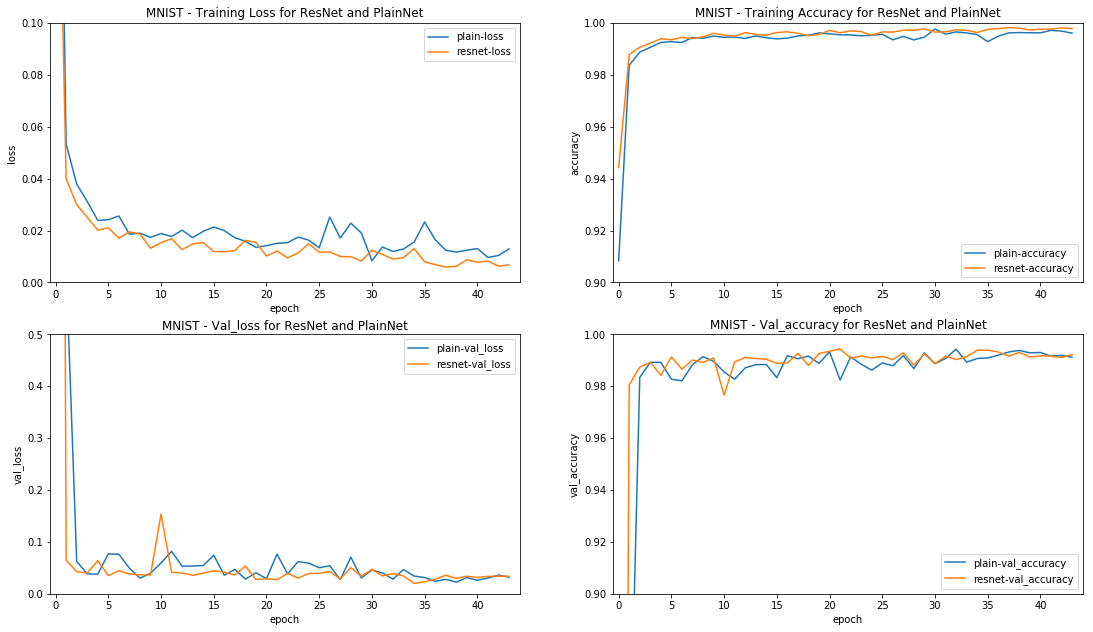

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.pyplot import figure


plainhist = np.genfromtxt("/Users/tomunterleiter/Desktop/ResNet/PlainNet/plainnet_mnist_values.csv", delimiter=",")
reshist = np.genfromtxt("/Users/tomunterleiter/Desktop/ResNet/ResNet/resnet_mnist_values.csv", delimiter=",")

index = np.arange(44)
fig, axs = plt.subplots(2, 2)

fig.set_size_inches(18.5, 10.5)

axs[0,0].plot(index, plainhist[0], label="plain-loss")
axs[0,0].plot(index, reshist[0], label="resnet-loss")
axs[0,0].set_xlabel("epoch")
axs[0,0].set_ylabel("loss")
axs[0,0].set_xlim(-0.5,44)
axs[0,0].set_ylim(0, 0.1)
#plt.xticks(index)
axs[0,0].legend()
axs[0,0].set_title('MNIST - Training Loss for ResNet and PlainNet')

axs[0,1].plot(index, plainhist[1], label="plain-accuracy")
axs[0,1].plot(index, reshist[1], label="resnet-accuracy")
axs[0,1].set_xlabel("epoch")
axs[0,1].set_ylabel("accuracy")
axs[0,1].set_xlim(-0.5,44)
axs[0,1].set_ylim(0.9, 1)
#plt.xticks(index)
axs[0,1].legend()
axs[0,1].set_title('MNIST - Training Accuracy for ResNet and PlainNet')

axs[1,0].plot(index, plainhist[2], label="plain-val_loss")
axs[1,0].plot(index, reshist[2], label="resnet-val_loss")
axs[1,0].set_xlabel("epoch")
axs[1,0].set_ylabel("val_loss")
axs[1,0].set_xlim(-0.5,44)
axs[1,0].set_ylim(0, 0.5)
#plt.xticks(index)
axs[1,0].legend()
axs[1,0].set_title('MNIST - Val_loss for ResNet and PlainNet')

axs[1,1].plot(index, plainhist[3], label="plain-val_accuracy")
axs[1,1].plot(index, reshist[3], label="resnet-val_accuracy")
axs[1,1].set_xlabel("epoch")
axs[1,1].set_ylabel("val_accuracy")
axs[1,1].set_xlim(-0.5,44)
axs[1,1].set_ylim(0.9, 1)
#plt.xticks(index)
axs[1,1].legend()
axs[1,1].set_title('MNIST - Val_accuracy for ResNet and PlainNet')
fig.show()
fig.savefig("/Users/tomunterleiter/Desktop/ResNet/MNIST_4plot")